# Bài Lab: Canny Edge Detector

## Mục tiêu
Triển khai thuật toán Canny Edge Detector phát hiện biên trong Thị giác máy tính. Thuật toán bao gồm ba giai đoạn chính:

1. **Tính gradient mịn (smoothed gradients).**
2. **Loại bỏ cực đại không tối ưu (Non-maximal Suppression).**
3. **Ngưỡng hóa phân cấp (Hysteresis Thresholding).**

Sử dụng Python cùng các thư viện như NumPy, SciPy, và Matplotlib để xử lý ảnh và trực quan hóa kết quả.


In [5]:
import numpy as np
import skimage
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage
from scipy.ndimage.filters import convolve
import os

/tmp/ipython-input-5-3033427389.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import convolve


In [3]:
def read_image(input_img):
    # Danh sách các định dạng
    supported_formats = ['.bmp', '.jpg', '.png']

    # Kiểm tra định dạng
    for fmt in supported_formats:
        input_path = os.path.join( input_img + fmt)
        if os.path.exists(input_path):
            with open(input_path, 'rb') as f:
                # Đọc dữ liệu ảnh
                image_data = f.read()
                # Xử lý ảnh tùy thuộc vào định dạng
                if fmt == '.bmp':
                    print("Đọc ảnh BMP")
                elif fmt == '.jpg':
                    print("Đọc ảnh JPG")
                elif fmt == '.png':
                    print("Đọc ảnh PNG")
                return input_path  # Trả về đường dẫn ảnh
    print("Không đọc được ảnh.")
    return None

## Phần 1: Tính Gradient (Smoothed Gradients)

### Mô tả
Mục tiêu là giảm nhiễu và tính toán gradient của ảnh để phát hiện các điểm có sự thay đổi cường độ lớn (cạnh).

### Yêu cầu

1. **Chuyển ảnh màu sang thang độ xám:**
   - Nếu ảnh đầu vào là ảnh RGB, chuyển sang thang độ xám để đơn giản hóa xử lý.

2. **Làm mịn ảnh bằng bộ lọc Gaussian:**
   - Áp dụng tích chập với Gaussian $(𝜎 = 1)$ để giảm nhiễu.

3. **Tính gradient theo hướng x và y:**
   - Dùng toán tử Sobel để tính 𝐼ₓ (gradient ngang) và 𝐼ᵧ (gradient dọc).

4. **Tính độ lớn và hướng gradient:**
   - Độ lớn gradient: $𝐹 = √(𝐼ₓ² + 𝐼ᵧ²)$.
   - Hướng gradient: $𝐷 = arctan(𝐼ᵧ / 𝐼ₓ)$.

### Công thức toán học

1. **Gaussian Kernel $(𝜎 = 1)$:**
   $$
   G(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}}
   $$
   Ma trận 3x3 xấp xỉ:
   $$
   G = \begin{bmatrix}
   0.1019 & 0.1154 & 0.1019 \\
   0.1154 & 0.1308 & 0.1154 \\
   0.1019 & 0.1154 & 0.1019
   \end{bmatrix}
   $$

2. **Toán tử Sobel:**
   $$
   Sₓ = \begin{bmatrix}
   -1 & 0 & 1 \\
   -2 & 0 & 2 \\
   -1 & 0 & 1
   \end{bmatrix}, \quad Sᵧ = \begin{bmatrix}
   1 & 2 & 1 \\
   0 & 0 & 0 \\
   -1 & -2 & -1
   \end{bmatrix}
   $$

3. **Gradient:**
   $$
   Iₓ = I * Sₓ, \quad Iᵧ = I * Sᵧ
   $$
   $$
   F = \sqrt{Iₓ² + Iᵧ²}, \quad D = \arctan{\left(\frac{Iᵧ}{Iₓ}\right)}
   $$


Đọc ảnh JPG


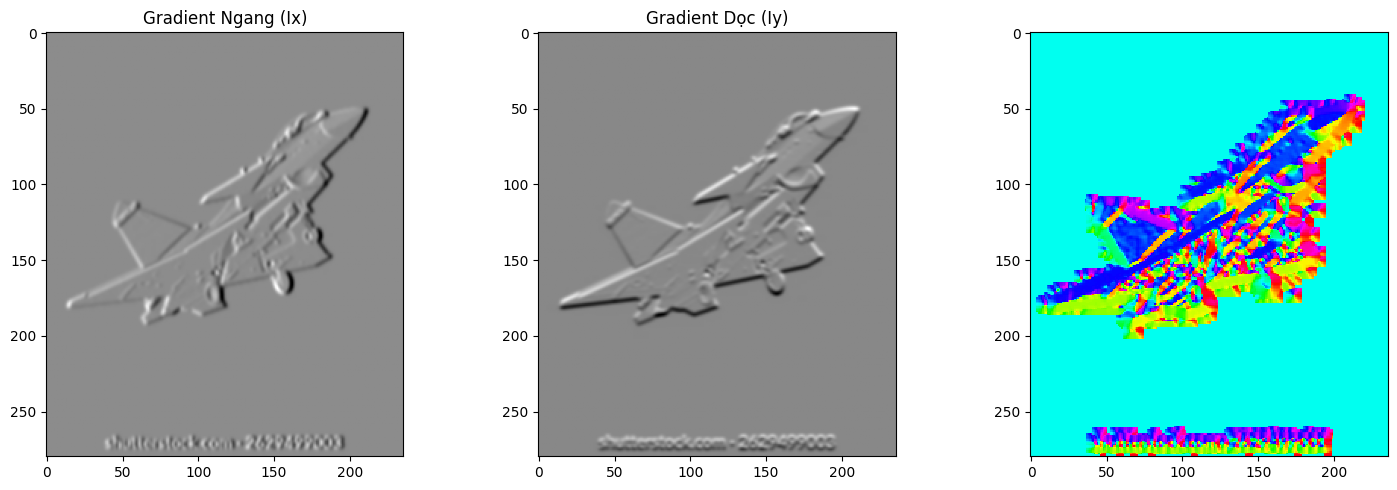

In [7]:
# Hàm chuyển đổi ảnh RGB sang xám
def rgb2gray(img):
    """
    Chuyển đổi ảnh RGB sang xám :
    Y = 0.2989R + 0.5870G + 0.1140B
    """
    return (np.dot(img[..., :3], [0.2989, 0.5870, 0.1140])).astype('float32')
def gaussian_kernel(size: int, sigma: float):
    """Tạo kernel Gauss 2D."""
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)
# Hàm tính gradient mịn với Sobel và hướng gradient
def convolveWithGaussianDerivative(img):
    """
    Tính gradient ngang (Ix) và dọc (Iy) bằng ma trận Sobel,
    và tính hướng gradient (theta_angle).
    """
    gauss_kernel = gaussian_kernel(5, 1)

    img = convolve(img, gauss_kernel)
    # Ma trận Sobel cho gradient ngang và dọc
    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float64)

    sobel_y = sobel_x.T

    # Tích chập ảnh với ma trận Sobel
    Ix = convolve(img, sobel_x)
    Iy = convolve(img, sobel_y)

    # Tính hướng gradient
    theta_angle = np.arctan2(Iy, Ix)
    return Ix, Iy, theta_angle

# Đọc ảnh đầu vào và xử lý
def process_image(input_img):
    """
    Đọc ảnh đầu vào, chuyển sang thang độ xám, tính gradient và lưu kết quả.
    """

    # Đọc ảnh
    input_path = read_image(input_img)
    if input_path is None:
        raise FileNotFoundError(f"Không tìm thấy ảnh với tên: {input_img}")

    # Đọc và chuẩn hóa ảnh
    img = skimage.io.imread(input_path) / 255.0
    img_gray = rgb2gray(img)



    # Tính gradient và hướng gradient
    Ix, Iy, theta_angle = convolveWithGaussianDerivative(img_gray)
    # Hiển thị kết quả
    plt.figure(figsize=(15, 5))

    # Gradient Ix
    plt.subplot(1, 3, 1)
    plt.imshow(Ix, cmap='gray')
    plt.title("Gradient Ngang (Ix)")

    # Gradient Iy
    plt.subplot(1, 3, 2)
    plt.imshow(Iy, cmap='gray')
    plt.title("Gradient Dọc (Iy)")

    # Hướng Gradient (theta)
    theta_display = (theta_angle + np.pi) / (2 * np.pi)
    plt.subplot(1, 3, 3)
    plt.imshow(theta_display, cmap="hsv", interpolation='none')

    plt.tight_layout()
    plt.show()

# Chạy hàm xử lý với tên ảnh đầu vào
input_img = 'tiemkich'
process_image(input_img)

## Phần 2: Non-maximal Suppression

### Mô tả
Phần này yêu cầu làm mỏng các cạnh bằng cách loại bỏ các điểm không phải cực đại theo hướng gradient, đảm bảo cạnh chỉ dày 1 pixel.

### Yêu cầu

1. **Xác định hướng gần đúng 𝐷∗:**
   - Góc 𝐷 được lượng tử hóa thành 4 hướng:
     
     0, π/4, π/2, 3π/4
      
     (tương ứng 0°, 45°, 90°,135°).

2. **So sánh độ lớn gradient:**
   - Với mỗi pixel, so sánh 𝐹[y,x] với hai láng giềng theo hướng 𝐷∗.
   - Nếu 𝐹[y,x] không lớn nhất, đặt 𝐼[y,x] = 0; ngược lại, giữ 𝐼[y,x] = 𝐹[y,x].

### Công thức

1. **Hướng gần đúng 𝐷∗:**
   - Nếu 𝐷 ∈ [0°, 22.5°) ∪ [157.5°, 180°) → 𝐷∗ = 0.
   - Nếu 𝐷 ∈ [22.5°, 67.5°) → 𝐷∗ = π/4.
   - Nếu 𝐷 ∈ [67.5°, 112.5°) → 𝐷∗ = π/2.
   - Nếu 𝐷 ∈ [112.5°, 157.5°) → 𝐷∗ = 3π/4.

2. **So sánh theo hướng:**
   - Ví dụ: Nếu 𝐷∗ = 0, so sánh 𝐹[y,x] với 𝐹[y,x+1] và 𝐹[y,x−1].


[[0.        0.        0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]
 ...
 [0.        0.        0.        ... 0.        0.        0.       ]
 [0.        2.4541612 2.4209473 ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]]


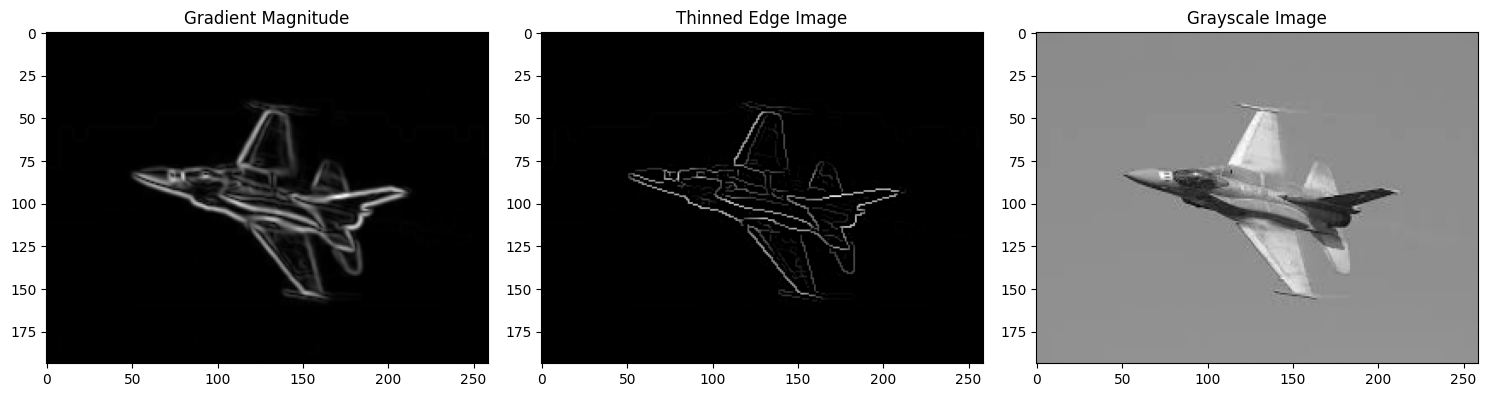

In [8]:
# Hàm chuyển đổi ảnh RGB sang thang độ xám
def rgb2gray(img):
    """
    Chuyển đổi ảnh RGB sang thang độ xám sử dụng công thức luminance:
    Y = 0.2989R + 0.5870G + 0.1140B
    """
    return (np.dot(img[..., :3], [0.2989, 0.5870, 0.1140])).astype('float32')

# # Hàm tính gradient mịn với Sobel và hướng gradient
# def convolveWithGaussianDerivative(img):
#     """
#     Tính gradient ngang (Ix) và dọc (Iy) bằng ma trận Sobel,
#     và tính hướng gradient (theta_angle).
#     """
#     sobel_x = None
#     sobel_y = None

#     Ix = None
#     Iy = None

#     theta_angle = None
#     return Ix, Iy, theta_angle

# Hàm Non-maximal Suppression
def Non_maximal_Suppression(Gradient, theta_angle):
    output = np.zeros(Gradient.shape, dtype=np.float32)  # Ảnh cạnh mỏng
    angle = np.degrees(theta_angle)  # Chuyển từ radian sang độ
    for i in range(1, Gradient.shape[0]-1):
        for j in range(1, Gradient.shape[1]-1):
            x, y = 1.0, 1.0
            if angle[i, j] < 0:
                angle[i, j] += 180  # Chuẩn hóa góc về [0, 180]
            # Xác định hướng gần đúng D*
            if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                x, y = Gradient[i, j+1], Gradient[i, j-1]
            elif (22.5 <= angle[i,j] < 67.5):
                x, y = Gradient[i+1, j+1], Gradient[i-1, j-1]
            elif (67.5 <= angle[i,j] < 112.5):
                x, y = Gradient[i+1, j], Gradient[i-1, j]
            elif (112.5 <= angle[i,j] < 157.5):
                x, y = Gradient[i-1, j+1], Gradient[i+1, j-1]
            # So sánh và giữ cực đại
            if (Gradient[i,j] >= x) and (Gradient[i,j] >= y):
                output[i,j] = Gradient[i,j]
            else:
                output[i,j] = 0.0
    return output

# Đọc ảnh đầu vào và xử lý
def process_image(input_img):
    """
    Đọc ảnh đầu vào, chuyển sang thang độ xám, tính gradient và áp dụng Non-maximal Suppression.
    """
    # Đường dẫn ảnh đầu vào
    input_path = input_img + '.jpg'

    # Kiểm tra file ảnh
    if not os.path.exists(input_path):
        raise FileNotFoundError(f"File ảnh không tìm thấy: {input_path}")

    # Đọc và chuẩn hóa ảnh
    img = skimage.io.imread(input_path)
    img_gray = rgb2gray(img)

    # # Lưu ảnh thang độ xám
    # output_dir = 'Results/canny_edge/'
    # None

    # Tính gradient và hướng gradient
    Ix, Iy, theta_angle = convolveWithGaussianDerivative(img_gray)
    Gradient = np.sqrt(Ix**2 + Iy**2)
    # plt.imsave(output_dir + input_img + '_gradient_magnitude.jpg', Gradient, cmap='gray')

    # Áp dụng Non-maximal Suppression
    thinned_edge_image = Non_maximal_Suppression(Gradient, theta_angle)
    # plt.imsave(output_dir + input_img + '_thinned_edge.jpg', thinned_edge_image, cmap='gray')
    print(thinned_edge_image)
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.title("Gradient Magnitude")
    plt.imshow(Gradient, cmap='gray')

    plt.subplot(1, 3, 2)
    plt.title("Thinned Edge Image")
    plt.imshow(thinned_edge_image, cmap='gray')

    plt.subplot(1, 3, 3)
    plt.title("Grayscale Image")
    plt.imshow(img_gray, cmap='gray')

    plt.tight_layout()
    plt.show()
# Chạy hàm xử lý ảnh
input_img = 'plane'
process_image(input_img)

## Phần 3: Hysteresis Thresholding

### Mô tả
Ở bước này sẽ thực hiện phân loại các pixel thành cạnh mạnh, cạnh yếu, hoặc không phải cạnh. Sau đó, kết nối các cạnh yếu với cạnh mạnh để tạo ra biên cuối cùng.

### Yêu cầu

1. **Áp dụng ngưỡng kép:**
   - 𝑇ₗₒw (ngưỡng thấp) và 𝑇ₕᵢgh (ngưỡng cao).
   - Nếu 𝐹 < 𝑇ₗₒw: Không phải cạnh (𝐼[y,x] = 0).
   - Nếu 𝐹 ≥ 𝑇ₕᵢgh: Cạnh mạnh (𝐼[y,x] = 1).
   - Nếu 𝑇ₗₒw ≤ 𝐹 < 𝑇ₕᵢgh: Cạnh yếu (𝐼[y,x] = 0.5).

2. **Kết nối cạnh yếu với cạnh mạnh:**
   - Duyệt qua 8 neighbourhood của các pixel mạnh. Nếu có cạnh yếu liền kề, chuyển thành cạnh mạnh.

### Công thức toán học

1. **Ngưỡng hóa:**
   $$
   I[y,x] =
   \begin{cases}
   0 & \text{nếu } F[y,x] < T_{low} \\
   0.5 & \text{nếu } T_{low} \leq F[y,x] < T_{high} \\
   1 & \text{nếu } F[y,x] \geq T_{high}
   \end{cases}
   $$

2. **Kiểm tra 8 neighbourhood:**
   Các hướng:
   $$
   (0,1), (0,-1), (-1,0), (1,0), (-1,-1), (1,-1), (-1,1), (1,1)
   $$


Đọc ảnh JPG


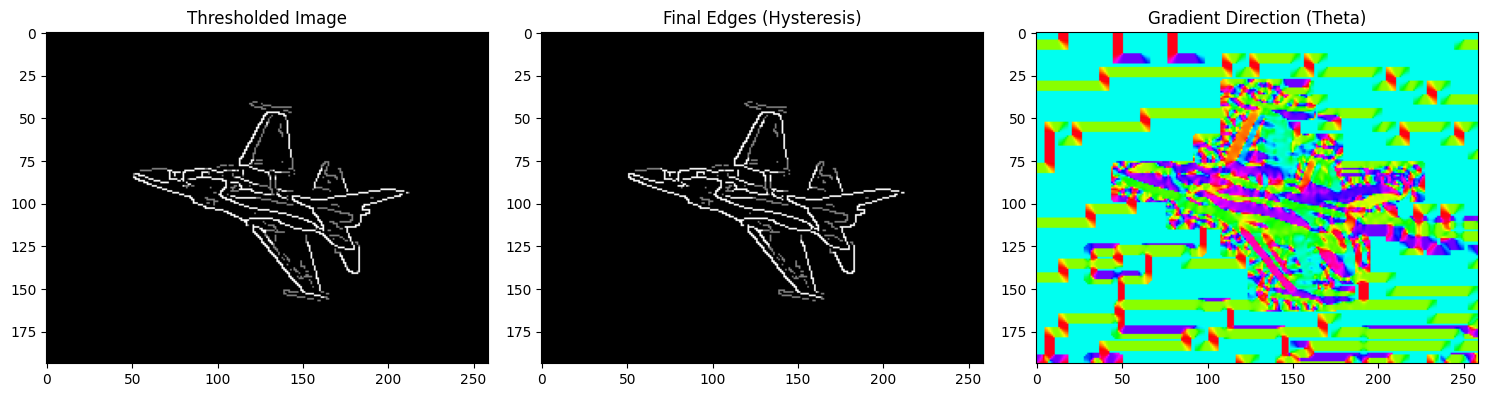

In [9]:
# Hàm threshold
def threshold(img, low_Th, high_Th):
    """
    Phân loại các điểm ảnh thành cạnh mạnh, cạnh yếu và không phải cạnh.
    """
    output = np.zeros(shape=img.shape)
    img = img / np.max(img)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            if img[i, j] < low_Th:
                output[i, j] = 0
            elif img[i, j] < high_Th:
                output[i, j] = 0.5
            else:
                output[i, j] = 1
    return output

# Hàm kiểm tra 8 neighbourhood
def check_8_neighbourhood(img, row, col):
    """
    Kiểm tra xem pixel yếu có cạnh mạnh nào trong 8 neighbourhood không.
    """
    for i in range(-1, 2):
        for j in range(-1, 2):
            if i==0 and j==0:
                continue
            if img[row+i, col+j] == 1.0:
                return True
    return False

# Hàm hysteresis
def perfom_hysteresis(img):
    """
    link các cạnh yếu với cạnh mạnh nếu cạnh link trong 8 neighbourhood.
    """
    _img = np.copy(img)
    dim1, dim2 = img.shape
    for i in range(1, dim1-1):
        for j in range(1, dim2-1):
            if _img[i, j] == 0.5 and check_8_neighbourhood(img, i, j):
                _img[i, j] = 1.0  # Chuyển cạnh yếu thành mạnh
    return _img

# Đọc ảnh đầu vào và xử lý
def process_image(input_img):
    """
    Đọc ảnh đầu vào, chuyển sang thang độ xám, tính gradient, áp dụng NMS, ngưỡng hóa và hysteresis.
    """

    # Đọc ảnh
    input_path = read_image(input_img)
    if input_path is None:
        raise FileNotFoundError(f"Không tìm thấy ảnh: {input_img}")

    # Đọc và chuẩn hóa ảnh
    img = skimage.io.imread(input_path)
    img_gray = rgb2gray(img)

    # Tính gradient và hướng gradient
    Ix, Iy, theta_angle = convolveWithGaussianDerivative(img_gray)

    # Tính độ lớn gradient
    Gradient = np.sqrt(Ix**2 + Iy**2)

    # Áp dụng Non-Maximal Suppression
    thinned_edge_image = Non_maximal_Suppression(Gradient, theta_angle)

    # Ngưỡng hóa
    low_Th, high_Th = 0.1, 0.25  # Ngưỡng thấp và cao
    thresholded_img = threshold(thinned_edge_image, low_Th, high_Th)

    # # Lưu ảnh sau khi ngưỡng hóa
    # output_dir = 'Results/canny_edge/'
    # None

    # Áp dụng hysteresis
    hystersis_img = perfom_hysteresis(thresholded_img)

    # Lưu ảnh cuối cùng
    # plt.imsave(os.path.join(output_dir, input_img + '_final_edges.jpg'), hystersis_img, cmap='gray')

    # Hiển thị kết quả
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.title("Thresholded Image")
    plt.imshow(thresholded_img, cmap='gray')

    plt.subplot(1, 3, 2)
    plt.title("Final Edges (Hysteresis)")
    plt.imshow(hystersis_img, cmap='gray')

    plt.subplot(1, 3, 3)
    plt.title("Gradient Direction (Theta)")
    plt.imshow(theta_angle, cmap='hsv')

    plt.tight_layout()
    plt.show()

input_img = 'plane'
process_image(input_img)